In [1]:
import os
import torch
import pandas as pd
import numpy as np
import cv2
from torch.utils.data import Dataset, DataLoader
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.transforms import functional as F
from tqdm import tqdm
from PIL import Image
from torch.utils.data import default_collate
device=device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [2]:
import os, random, glob, pandas as pd, xml.etree.ElementTree as ET
from sklearn.model_selection import train_test_split

def get_file_list(root, extensions):
    files = []
    for ext in extensions: files += glob.glob(os.path.join(root, "**", ext), recursive=True)
    return sorted(files)

def parse_voc_annotations(dataset_root):
    img_paths = get_file_list(dataset_root, ["*.jpg", "*.jpeg", "*.png", "*.bmp", "*.webp"])
    xml_paths = get_file_list(dataset_root, ["*.xml"])
    img_lookup = {os.path.splitext(os.path.basename(p))[0]: p for p in img_paths}
    dataset_records = []
    for xml_file in xml_paths:
        try:
            root = ET.parse(xml_file).getroot()
            img_id = os.path.splitext(os.path.basename(root.findtext("filename", "")))[0]
            if img_id not in img_lookup: continue
            for obj in root.findall("object"):
                bbox = obj.find("bndbox")
                if bbox is None: continue
                dataset_records.append({
                    "image_path": img_lookup[img_id], "label": obj.findtext("name", "obj").strip(),
                    "coords": (int(float(bbox.findtext("xmin", "0"))), int(float(bbox.findtext("ymin", "0"))),
                               int(float(bbox.findtext("xmax", "1"))), int(float(bbox.findtext("ymax", "1"))))
                })
        except: continue
    return dataset_records, img_paths

# Khởi tạo đường dẫn
EXPORT_DIR, DATA_SOURCE = "/kaggle/working/splits", "/kaggle/input/datasets/andrewmvd/face-mask-detection"
os.makedirs(EXPORT_DIR, exist_ok=True)
random.seed(42)

# Load và chia dữ liệu
all_records, _ = parse_voc_annotations(DATA_SOURCE)
unique_images = sorted({r["image_path"] for r in all_records})
train_set, temp_set = train_test_split(unique_images, train_size=0.7, random_state=42)
val_set, test_set = train_test_split(temp_set, train_size=0.5, random_state=42)
split_map = {p: "train" for p in train_set} | {p: "valid" for p in val_set} | {p: "test" for p in test_set}

# Tạo DataFrame
structured_data = [{
    "split": split_map[r["image_path"]], "path": r["image_path"], "file_name": os.path.basename(r["image_path"]),
    "class": r["label"], "x1": r["coords"][0], "y1": r["coords"][1], "x2": r["coords"][2], "y2": r["coords"][3]
} for r in all_records]

df_main = pd.DataFrame(structured_data)

# Xuất file & Thống kê
df_main.to_csv(f"{EXPORT_DIR}/all_data.csv", index=False)
for s in ["train", "valid", "test"]: df_main[df_main["split"] == s].to_csv(f"{EXPORT_DIR}/{s}.csv", index=False)

print(f"Summary: {len(unique_images)} images split into Train({len(train_set)}), Val({len(val_set)}), Test({len(test_set)})")

Summary: 853 images split into Train(597), Val(128), Test(128)


In [3]:
# --- 1. CẤU HÌNH ---
TRAIN_CSV = "/kaggle/working/splits/train.csv"
VALID_CSV = "/kaggle/working/splits/valid.csv"
OUTPUT_CSV = "/kaggle/working/dl_valid_results.csv"
DEVICE = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

In [4]:
import torch
from torchvision import transforms, datasets
from torch.utils.data import DataLoader

import albumentations as A
from albumentations.pytorch import ToTensorV2

train_tf = A.Compose([
    A.Resize(224,224),
    A.HorizontalFlip(p=0.5),
    A.Normalize(
        mean=(0.485,0.456,0.406),
        std=(0.229,0.224,0.225)
    ),
    ToTensorV2()
],
bbox_params=A.BboxParams(
    format='pascal_voc',
    label_fields=['labels']
))

val_tf = A.Compose([
    A.Resize(224,224),
    A.Normalize(
        mean=(0.485,0.456,0.406),
        std=(0.229,0.224,0.225)
    ),
    ToTensorV2()
],
bbox_params=A.BboxParams(
    format='pascal_voc',
    label_fields=['labels']
))

In [5]:
# --- 2. DATASET CLASS ---
class FaceMaskDataset(Dataset):
    def __init__(self, csv_path,transform):
        self.df = pd.read_csv(csv_path)
        cols = self.df.columns
        self.col_path = next((c for c in cols if 'path' in c.lower()), None)
        self.col_class = next((c for c in cols if 'class' in c.lower() or 'label' in c.lower()), None)
        
        if not self.col_path: raise KeyError("Không tìm thấy cột chứa đường dẫn ảnh (ví dụ: 'image_path')")

        self.transform=transform
        self.img_paths = self.df[self.col_path].unique()
        self.classes = {name: i+1 for i, name in enumerate(self.df[self.col_class].unique())}
        self.num_classes = len(self.classes) + 1

    def __getitem__(self, idx):
        img_p = self.img_paths[idx]
        img = cv2.imread(img_p)
        if img is None: 
            return torch.zeros((3, 224, 224)), {"boxes": torch.zeros((0, 4)), "labels": torch.zeros(0)}, img_p
            
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        # img_pil = Image.fromarray(img)
       
        
        # Lấy bản ghi của ảnh hiện tại
        records = self.df[self.df[self.col_path] == img_p]
        boxes = records[['x1', 'y1', 'x2', 'y2']].values
        boxes = np.array(boxes, dtype=np.float32)
        
        labels = [self.classes[name] for name in records[self.col_class].values]

        # print(boxes[:3])
        #loc anh loi
        h, w = img.shape[:2]
        
        boxes = np.array(boxes, dtype=np.float32)
        
        boxes[:,0] = np.clip(boxes[:,0], 0, w-1)
        boxes[:,1] = np.clip(boxes[:,1], 0, h-1)
        boxes[:,2] = np.clip(boxes[:,2], 0, w-1)
        boxes[:,3] = np.clip(boxes[:,3], 0, h-1)
        
        valid_boxes = []
        valid_labels = []
        
        for b,l in zip(boxes, labels):
            x1,y1,x2,y2 = b
            if x2 > x1 and y2 > y1:
                valid_boxes.append(b)
                valid_labels.append(l)
        
        boxes = valid_boxes
        labels = valid_labels
        
        aug = self.transform(
            image=img,
            bboxes=boxes,
            labels=labels
        )
        
        img = aug["image"]
        
        target = {
            "boxes": torch.tensor(aug["bboxes"], dtype=torch.float32),
            "labels": torch.tensor(aug["labels"], dtype=torch.int64)
        }
        print(target["boxes"][:3])
        print(target["boxes"].dtype)
        
        print(target["labels"][:3])
        print(target["labels"].dtype)
        
        return img, target, img_p

    def __len__(self):
        return len(self.img_paths)



In [6]:
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn

from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

train_dataset=FaceMaskDataset(TRAIN_CSV,transform=train_tf)
val_dataset=FaceMaskDataset(VALID_CSV,transform=val_tf)
num_classes = train_dataset.num_classes
def get_model(num_classes):
    # Load model pre-trained
    model = fasterrcnn_resnet50_fpn(pretrained=True)
    
    # Lấy số đặc trưng đầu vào của lớp phân loại[cite: 1]
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    
    # Thay thế đầu ra phù hợp với số lớp của bạn[cite: 1]
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
    
    return model

# Sau đó khởi tạo model với biến num_classes đã lấy ở trên[cite: 1]
model = get_model(num_classes)

def collate_fn(batch):
    return tuple(zip(*batch))

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 207MB/s]


In [7]:
def iou(a,b):
    x1=max(a[0],b[0]);y1=max(a[1],b[1])
    x2=min(a[2],b[2]);y2=min(a[3],b[3])
    inter=max(0,x2-x1)*max(0,y2-y1)
    sa=(a[2]-a[0])*(a[3]-a[1])
    sb=(b[2]-b[0])*(b[3]-b[1])
    return inter/(sa+sb-inter+1e-6)

def match_iou(pb,tb):
    if len(pb)==0 or len(tb)==0: return 0
    used=[0]*len(tb)
    res=[]
    for p in pb:
        best=0;idx=-1
        for i,g in enumerate(tb):
            if used[i]: continue
            v=iou(p,g)
            if v>best: best=v;idx=i
        if idx!=-1:
            used[idx]=1
            res.append(best)
    return sum(res)/len(res) if res else 0

In [8]:
def evaluate(m,dl,dev):
    m.eval()
    tl=0;acc=[]

    with torch.no_grad():
        for imgs,tg,_ in dl:
            imgs=[i.to(dev) for i in imgs]
            tg=[{k:v.to(dev) for k,v in t.items()} for t in tg]

            # loss
            m.train()
            ld=m(imgs,tg)
            loss=sum(v for v in ld.values())
            tl+=loss.item()

            # predict
            m.eval()
            out=m(imgs)

            for o,t in zip(out,tg):
                pb=o['boxes'].cpu().numpy()
                tb=t['boxes'].cpu().numpy()
                acc.append(match_iou(pb,tb))

    return tl/len(dl), (sum(acc)/len(acc) if acc else 0)

In [9]:

# model=get_model()

train_loader=DataLoader(train_dataset,batch_size=16,shuffle=True,collate_fn=collate_fn)
val_loader=DataLoader(val_dataset,batch_size=16,shuffle=False,collate_fn=collate_fn)
# train_dataset=FaceMaskDataset(TRAIN_CSV)
# train_loader=DataLoader(train_dataset,batch_size=32,shuffle=True,collate_fn=collate_fn)


def train_model(model, train_loader, val_loader, device, num_epochs=10, lr=0.005):
    model.to(device)
    
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=0.0005)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)
    
    for epoch in range(num_epochs):
        model.train()
        total_loss = 0.0
        train_ious = []
        
        for images, targets, paths in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}"):
            images = [img.to(device) for img in images]
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

            loss_dict = model(images, targets)
            losses = sum(loss for loss in loss_dict.values())

            optimizer.zero_grad()
            losses.backward()
            optimizer.step()

            total_loss += losses.item()

            model.eval()
            with torch.no_grad():
                outputs = model(images)
                for o, t in zip(outputs, targets):
                    pb = o['boxes'].cpu().numpy()
                    tb = t['boxes'].cpu().numpy()
                    train_ious.append(match_iou(pb, tb))
            model.train()

        avg_loss = total_loss / len(train_loader)
        train_acc = sum(train_ious)/len(train_ious) if train_ious else 0

        val_loss, val_acc = evaluate(model, val_loader, device)

        scheduler.step()

        print(f"Epoch {epoch+1}")
        print(f"Train Loss: {avg_loss:.4f} | Train IoU: {train_acc:.4f}")
        print(f"Val   Loss: {val_loss:.4f} | Val   IoU: {val_acc:.4f}")
        
    return model

In [10]:
print(num_classes)


4


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.6399999].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.6225708].


tensor([[ 83.3488,  52.0800, 153.3023, 122.6400]])
torch.float32
tensor([2])
torch.int64
tensor([[154.5600,  52.3932, 164.6400,  67.5797],
        [129.9200,  22.7797, 140.5600,  40.2441],
        [ 72.2400,  30.3729,  86.2400,  52.3932]])
torch.float32
tensor([1, 1, 2])
torch.int64


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0494049..2.6399999].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9466563..2.5702832].


tensor([[137.5571,  37.5200, 178.8993,  65.5200],
        [ 44.3490,  43.1200,  84.9396,  75.0400]])
torch.float32
tensor([2, 3])
torch.int64
tensor([[107.3858,  25.7600, 126.6816,  43.1200],
        [  5.8727,  87.3600,  15.9401,  99.1200],
        [ 16.7790,  91.2800,  31.8801, 102.4800]])
torch.float32
tensor([2, 1, 1])
torch.int64


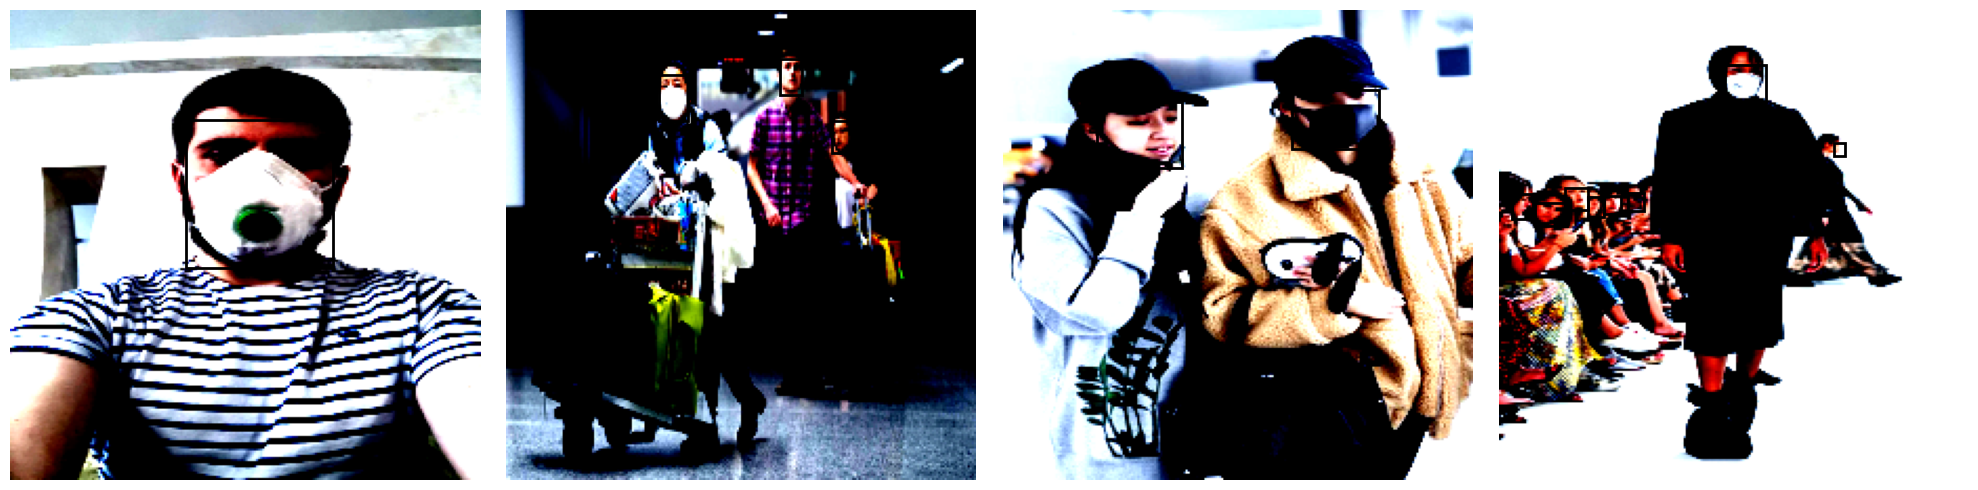

In [11]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random

def show_samples(dataset, n=4):
    fig, axes = plt.subplots(1, n, figsize=(5*n,5))

    if n == 1:
        axes = [axes]

    ids = random.sample(range(len(dataset)), n)

    for ax, idx in zip(axes, ids):
        img, target, _ = dataset[idx]

        img = img.permute(1,2,0).cpu().numpy()

        ax.imshow(img)
        ax.axis("off")

        boxes = target["boxes"]

        for b in boxes:
            x1, y1, x2, y2 = b.tolist()

            rect = patches.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=2,
                fill=False
            )

            ax.add_patch(rect)

    plt.tight_layout()
    plt.show()

show_samples(train_dataset, 4)

In [12]:
imgs, targets, _ = next(iter(train_loader))

print(targets[0]["boxes"][:5])

tensor([[ 98.2326, 110.3200, 171.1628, 180.3200]])
torch.float32
tensor([2])
torch.int64
tensor([[ 98.5600,  78.8614, 125.4400, 125.0037],
        [207.7600,  90.6067, 223.4400, 120.8090]])
torch.float32
tensor([2, 1])
torch.int64
tensor([[105.2800,  55.4381, 134.9600,  98.1405]])
torch.float32
tensor([2])
torch.int64
tensor([[ 59.5349, 113.6800, 141.3953, 198.8000]])
torch.float32
tensor([2])
torch.int64
tensor([[171.3600,  40.3200, 200.4800,  82.1333],
        [ 91.8400,  34.3467, 118.7200,  79.1467],
        [ 54.3200,  65.7067,  77.8400,  97.0667]])
torch.float32
tensor([2, 2, 2])
torch.int64
tensor([[ 66.2326, 159.0400, 130.9767, 223.4400]])
torch.float32
tensor([1])
torch.int64
tensor([[ 95.7600,  73.6000, 133.8400, 153.6000]])
torch.float32
tensor([3])
torch.int64
tensor([[169.6800,  65.4382, 187.6000,  95.6404],
        [151.2000,  91.4457, 161.8400, 109.0637],
        [100.2400,  34.3970, 122.0800,  69.6330]])
torch.float32
tensor([2, 2, 2])
torch.int64
tensor([[ 91.4457,  26.

In [13]:
model = get_model(num_classes+1)   # ví dụ: FasterRCNN, YOLO custom,...

model = train_model(model, train_loader, val_loader, device, 10, 1e-4)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Epoch 1/10:   0%|          | 0/38 [00:00<?, ?it/s]

tensor([[  0.5600,  73.9200,  33.0400, 120.4000],
        [ 77.8400,  71.6800, 125.4400, 117.6000],
        [185.3600, 114.8000, 223.4400, 155.1200]])
torch.float32
tensor([2, 2, 2])
torch.int64
tensor([[ 97.3184,  20.1600, 120.8090,  39.7600]])
torch.float32
tensor([2])
torch.int64
tensor([[ 49.8400, 117.6000, 100.8000, 169.6800]])
torch.float32
tensor([2])
torch.int64
tensor([[204.4000, 117.9733, 215.6000, 139.6267],
        [184.8000,  94.0800, 198.2400, 114.2400],
        [156.8000,  73.9200, 172.4800,  98.5600]])
torch.float32
tensor([2, 2, 2])
torch.int64
tensor([[101.9535, 110.8800, 181.5814, 184.8000]])
torch.float32
tensor([2])
torch.int64
tensor([[157.9200,  35.2756, 171.3600,  48.7979],
        [141.6800,  42.3307, 154.5600,  54.6772],
        [119.8400,  25.8688, 136.0800,  45.8583]])
torch.float32
tensor([2, 2, 2])
torch.int64
tensor([[ 74.4800,  90.6067,  82.8800, 104.0300],
        [113.6800,  98.1573, 119.8400, 109.9026],
        [164.6400,  96.4794, 172.4800, 109.0637]

Epoch 1/10:   3%|▎         | 1/38 [00:05<03:27,  5.60s/it]

tensor([[ 89.0400,  55.4381, 118.7200,  98.1405]])
torch.float32
tensor([2])
torch.int64
tensor([[ 75.9070, 126.5600, 152.5581, 196.0000]])
torch.float32
tensor([2])
torch.int64
tensor([[ 15.1200,  26.8464,  52.0800,  84.7341],
        [ 92.4000,  72.1498, 105.8400,  93.1236],
        [129.3600,  74.6667, 145.0400, 106.5468]])
torch.float32
tensor([2, 2, 2])
torch.int64
tensor([[ 47.0400,  91.8400, 108.6400, 190.4000],
        [107.5200,  79.5200, 166.8800, 209.4400]])
torch.float32
tensor([2, 2])
torch.int64
tensor([[189.8400,  43.6106, 198.2400,  68.3894],
        [197.6800,  97.1327, 203.8400, 119.9292],
        [176.9600, 137.7699, 182.0000, 158.5841]])
torch.float32
tensor([2, 2, 2])
torch.int64
tensor([[  2.8000, 132.8142,  40.8800, 204.1770],
        [ 47.6000, 116.9557,  70.5600, 159.5752],
        [ 60.4800,  73.3451,  75.0400,  97.1327]])
torch.float32
tensor([2, 2, 1])
torch.int64
tensor([[ 36.4000,  53.0133,  56.0000,  84.3733],
        [ 75.0400,  45.5467,  85.6800,  65.70

Epoch 1/10:   5%|▌         | 2/38 [00:09<02:46,  4.63s/it]

...

tensor([[58.8000, 17.1733, 95.2000, 71.6800]])
torch.float32
tensor([2])
torch.int64
tensor([[ 41.4400,  57.6266,  67.2000, 104.0996]])
torch.float32
tensor([2])
torch.int64
tensor([[ 83.4400,  33.5581, 103.0400,  68.7940],
        [139.4400,  45.3034, 160.1600,  76.3446]])
torch.float32
tensor([2, 3])
torch.int64
tensor([[118.1600,  62.7200, 135.5200,  98.5600],
        [ 89.0400,  55.7511, 113.1200, 103.5378],
        [  5.6000, 107.5200,  15.6800, 127.4311]])
torch.float32
tensor([2, 2, 1])
torch.int64
tensor([[ 99.6800,  34.8444, 148.4000, 132.4089]])
torch.float32
tensor([1])
torch.int64
tensor([[116.0930,  93.5200, 192.7442, 170.2400]])
torch.float32
tensor([2])
torch.int64
tensor([[125.4400,  64.9600, 161.2800, 107.5200],
        [ 59.3600,  54.5067, 100.8000,  99.3067]])
torch.float32
tensor([2, 2])
torch.int64
tensor([[157.3600,  28.2074, 171.9200,  50.6074],
        [112.5600,  51.4370, 126.5600,  76.3259],
        [ 77.2800,  75.4963,  92.9600,  97.8963]])
torch.float32
tens

Epoch 10/10:  97%|█████████▋| 37/38 [02:59<00:04,  4.89s/it]

tensor([[ 78.8614,  31.9200, 140.1049,  73.3600]])
torch.float32
tensor([2])
torch.int64
tensor([[ 86.2400,  78.9333, 127.6800, 156.8000]])
torch.float32
tensor([2])
torch.int64
tensor([[  7.0275,  35.1220,  29.8667,  78.0488],
        [ 26.7922,  60.0976,  44.8000, 103.8049],
        [106.7294,  46.8293, 141.4274, 108.4878]])
torch.float32
tensor([2, 2, 2])
torch.int64
tensor([[ 65.2427,  44.8000, 153.6828, 138.3200]])
torch.float32
tensor([3])
torch.int64
tensor([[14.0000, 10.9064, 19.6000, 20.9738],
        [30.8000,  8.3895, 36.4000, 16.7790],
        [67.2000, 13.4232, 72.8000, 26.0075]])
torch.float32
tensor([2, 2, 2])
torch.int64


Epoch 10/10: 100%|██████████| 38/38 [03:01<00:00,  4.77s/it]


tensor([[ 87.8139,  84.5600, 160.7442, 156.2400]])
torch.float32
tensor([1])
torch.int64
tensor([[ 69.2093, 102.4800, 144.3721, 165.2000]])
torch.float32
tensor([1])
torch.int64
tensor([[ 57.6800,   8.0640,  67.2000,  29.5680],
        [110.8800,  13.4400, 122.0800,  32.2560],
        [125.4400,  79.7440, 136.0800,  97.6640]])
torch.float32
tensor([1, 2, 2])
torch.int64
tensor([[ 36.9600,  19.7880,  45.9200,  37.9929],
        [ 56.5600,  32.4523,  69.4400,  53.8233],
        [ 96.8800,  26.9117, 108.0800,  47.4912]])
torch.float32
tensor([2, 2, 2])
torch.int64
tensor([[  2.8000, 113.4933,  32.4800, 177.2089],
        [ 70.0000,  81.6356,  76.1600,  94.5778],
        [ 87.9200,  81.6356,  95.2000,  98.5600]])
torch.float32
tensor([2, 2, 2])
torch.int64
tensor([[113.1163, 146.7200, 163.7209, 205.5200]])
torch.float32
tensor([2])
torch.int64
tensor([[115.9200,  68.3200, 202.1600, 162.9600]])
torch.float32
tensor([2])
torch.int64
tensor([[ 24.6400,  51.8824,  53.2000,  96.3529],
        [